# Week 3 Assignment: CIFAR-10 with a Pretrained ConvNet

## Fast feature extraction with VGG16

This notebook uses a pretrained VGG16 convolutional base to extract image representations from CIFAR-10. The convolutional base is loaded without its original Dense classifier, its ImageNet weights are frozen, and a new fully connected classifier is trained on the extracted features.

The test set is kept separate and is used only for the final evaluation.

## 1. Dataset and reproducibility

CIFAR-10 contains 60,000 colour images of size 32×32×3 belonging to ten mutually exclusive classes. The official Keras split contains 50,000 training images and 10,000 test images. The 50,000 training images are further divided into 40,000 training images and 10,000 validation images.

The labels remain integer class IDs from 0 to 9, so sparse categorical cross-entropy is used later.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers, Sequential
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

keras.utils.set_random_seed(42)

num_classes = 10
image_shape = (32, 32, 3)

(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_all = y_all.squeeze().astype('int64')
y_test = y_test.squeeze().astype('int64')

# Shuffle only the original training portion before creating train/validation sets.
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_all))
x_all = x_all[indices]
y_all = y_all[indices]

x_train, x_val = x_all[:40000], x_all[40000:]
y_train, y_val = y_all[:40000], y_all[40000:]

print('Training:', x_train.shape, y_train.shape)
print('Validation:', x_val.shape, y_val.shape)
print('Test:', x_test.shape, y_test.shape)
print('Classes:', np.unique(y_train))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2199s 13us/step
Training: (40000, 32, 32, 3) (40000,)
Validation: (10000, 32, 32, 3) (10000,)
Test: (10000, 32, 32, 3) (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


## 2. Pretrained convolutional base

VGG16 is loaded with ImageNet weights and `include_top=False`, so its original 1000-class Dense classifier is removed. The convolutional base is frozen: its weights are not updated while the new classifier is trained.

The CIFAR-10 images are only 32×32, which is the smallest spatial input size accepted by this VGG16 configuration. `pooling='avg'` applies global average pooling to the final convolutional feature maps and produces one compact 512-dimensional vector per image.

VGG16 expects its application-specific preprocessing, so `preprocess_input` is applied before feature extraction.

In [3]:
conv_base = VGG16(
    weights='imagenet',
    include_top=False, # Do not include the fully-connected layer at the top of the network. 
    input_shape=image_shape,
    pooling='avg'
)
conv_base.trainable = False # Freeze the convolutional base 

print('Trainable convolutional-base weights:', conv_base.trainable)
conv_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step
Trainable convolutional-base weights: False


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## 3. Fast feature extraction

The frozen VGG16 base is used as a feature extractor. This is done once for each split. The resulting arrays, rather than the original images, are used to train the fully connected classifier.

No augmentation is used in this feature-extraction approach. This follows the assignment's requested method, *fast feature extraction without data augmentation*.

In [4]:
def extract_features(images, labels, batch_size=128):
    images = preprocess_input(images.astype('float32'))
    features = conv_base.predict(images, batch_size=batch_size, verbose=1)
    return features.astype('float32'), labels

train_features, y_train = extract_features(x_train, y_train)
val_features, y_val = extract_features(x_val, y_val)
test_features, y_test = extract_features(x_test, y_test)

print('Extracted training features:', train_features.shape)
print('Extracted validation features:', val_features.shape)
print('Extracted test features:', test_features.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 63s 201ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 196ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 216ms/step
Extracted training features: (40000, 512)
Extracted validation features: (10000, 512)
Extracted test features: (10000, 512)


## 4. Compact hyperparameter experiment

A few small classifier experiments are run on the extracted training and validation features. Only the compact comparison table is retained; detailed training printouts and separate plots for every trial are intentionally omitted. The selection criterion is the best validation accuracy, and the test set is not used.

The candidate settings vary the hidden-layer width, dropout rate, and learning rate. After the short comparison, the configuration with the highest validation accuracy is selected and trained properly in the next section.

In [5]:
def build_classifier(hidden_units, dropout_rate, learning_rate):
    classifier = Sequential([
        layers.Input(shape=(train_features.shape[1],)),
        layers.Dense(hidden_units, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(num_classes, activation='softmax')
    ])
    classifier.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return classifier

trial_configs = [
    {'name': 'A', 'hidden_units': 128, 'dropout': 0.30, 'learning_rate': 1e-3},
    {'name': 'B', 'hidden_units': 256, 'dropout': 0.50, 'learning_rate': 1e-3},
    {'name': 'C', 'hidden_units': 512, 'dropout': 0.50, 'learning_rate': 3e-4},
]

trial_results = []
for trial in trial_configs:
    keras.utils.set_random_seed(42)
    trial_model = build_classifier(
        trial['hidden_units'], trial['dropout'], trial['learning_rate']
    )
    trial_history = trial_model.fit(
        train_features, y_train,
        validation_data=(val_features, y_val),
        epochs=12, batch_size=128, verbose=0
    )
    trial_results.append({
        **trial,
        'best_val_accuracy': max(trial_history.history['val_accuracy'])
    })

best_trial = max(trial_results, key=lambda result: result['best_val_accuracy'])
print('Compact hyperparameter comparison:')
for result in trial_results:
    print(
        f"{result['name']}: units={result['hidden_units']}, "
        f"dropout={result['dropout']:.2f}, lr={result['learning_rate']:.0e}, "
        f"best validation accuracy={result['best_val_accuracy']:.4f}"
    )

selected_hidden_units = best_trial['hidden_units']
selected_dropout = best_trial['dropout']
selected_learning_rate = best_trial['learning_rate']
print('Selected configuration:', best_trial)

classifier = build_classifier(
    selected_hidden_units, selected_dropout, selected_learning_rate
)
classifier.summary()

Compact hyperparameter comparison:
A: units=128, dropout=0.30, lr=1e-03, best validation accuracy=0.6549
B: units=256, dropout=0.50, lr=1e-03, best validation accuracy=0.6651
C: units=512, dropout=0.50, lr=3e-04, best validation accuracy=0.6727
Selected configuration: {'name': 'C', 'hidden_units': 512, 'dropout': 0.5, 'learning_rate': 0.0003, 'best_val_accuracy': 0.6726999878883362}


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 267,786 (1.02 MB)

 Trainable params: 267,786 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training the selected fully connected classifier

The compact experiment above selects the classifier using validation accuracy. The selected classifier is now trained for longer, with early stopping and learning-rate reduction. The convolutional base remains frozen, so only the fully connected classifier is optimized.

In [6]:
early_stopping = EarlyStopping(monitor='val_loss', patience=8, mode='min',restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, mode='min', min_lr=1e-6)

history = classifier.fit(train_features, y_train, validation_data=(val_features, y_val), epochs=60, batch_size=128, callbacks=[early_stopping, reduce_lr], verbose=1)

Epoch 1/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4219 - loss: 6.3328 - val_accuracy: 0.5798 - val_loss: 1.9181 - learning_rate: 3.0000e-04
Epoch 2/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5021 - loss: 2.1601 - val_accuracy: 0.5817 - val_loss: 1.3454 - learning_rate: 3.0000e-04
Epoch 3/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5369 - loss: 1.5130 - val_accuracy: 0.6016 - val_loss: 1.2113 - learning_rate: 3.0000e-04
Epoch 4/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5799 - loss: 1.2887 - val_accuracy: 0.6175 - val_loss: 1.1449 - learning_rate: 3.0000e-04
Epoch 5/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6089 - loss: 1.1614 - val_accuracy: 0.6291 - val_loss: 1.1055 - learning_rate: 3.0000e-04
Epoch 6/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6342 - loss: 1.0768 - val_accuracy: 0.6382 - val_loss: 1.0802 - learning_rate: 3.0000e-04
Epoch 7/60
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 

## 6. Training graphs

The graphs compare the classifier's training and validation accuracy and loss. The validation curves are the important indicators of generalization and were used for model selection.

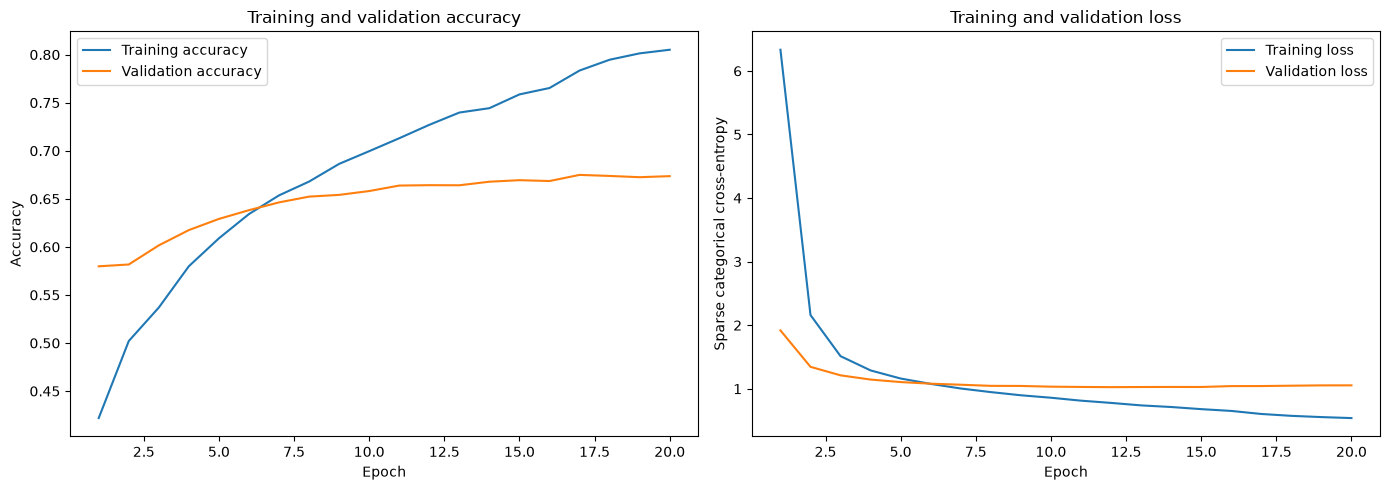

Best validation accuracy: 0.6749 at epoch 17


In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, acc, label='Training accuracy')
axes[0].plot(epochs, val_acc, label='Validation accuracy')
axes[0].set_title('Training and validation accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(epochs, loss, label='Training loss')
axes[1].plot(epochs, val_loss, label='Validation loss')
axes[1].set_title('Training and validation loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Sparse categorical cross-entropy')
axes[1].legend()

plt.tight_layout()
plt.show()

best_epoch = int(np.argmax(val_acc) + 1)
best_val_accuracy = float(np.max(val_acc))
print(f'Best validation accuracy: {best_val_accuracy:.4f} at epoch {best_epoch}')

## 7. Final test evaluation

The test set has not been used to choose the pretrained base, classifier architecture, or hyperparameters. It is used once here to report the final generalization accuracy.

In [8]:
test_loss, test_accuracy = classifier.evaluate(
    test_features, y_test, verbose=1
)
print(f'Final test accuracy: {test_accuracy:.4f}')
print(f'Final test loss: {test_loss:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6605 - loss: 1.0427
Final test accuracy: 0.6605
Final test loss: 1.0427


## Conclusion

VGG16 was used as a frozen pretrained convolutional base without its original classifier top. The CIFAR-10 images were converted into 512-dimensional feature vectors, and a small fully connected classifier was trained using the training features and validation data. Hyperparameters were selected using validation accuracy, training curves were presented, and the independent test set was used only for the final accuracy report.

The accuracy may not be extremely high because CIFAR-10 images are very small and differ substantially from the ImageNet images on which VGG16 was pretrained. Nevertheless, the experiment demonstrates transfer learning by reusing a learned visual representation and training a new task-specific classifier.